# Equipo 19 · Avance 3: prueba de entrenamiento con la máscara de Arnold et al. (2010)

En el Avance 2, Endo-STTN se usa **tal como se publicó** (`gen_00009.pth`), entrenado con videos reales de
HyperKvasir. C3VDv2 son modelos de silicona: otra textura, otro color y otros reflejos. Aquí se **reentrena**
Endo-STTN con frames de C3VDv2 para que rellene mejor los reflejos de este dominio.

| Paso | Script (`Avance3_ReEntrenar_Endo/`) | Qué hace |
|---|---|---|
| 1 | `preparar_endosttn.py` | Frames y **máscaras de reflejos** de C3VDv2 en el formato de Endo-STTN (288×288), división por segmento |
| 2 | `entrenar_endosttn.py` | Entrenamiento original de Endo-STTN (generador + discriminador), partiendo de `gen_00009.pth` |
| 3 | `evaluar_endosttn.py` | Original vs reentrenado en videos no vistos, con *pseudo ground truth* |

**¿Hay que generar máscaras?** Sí, dos, y las dos salen solas:
1. **Máscara de reflejos** de cada frame. Este notebook usa **Arnold et al. (2010)** (`MASCARA = "arnold"`). Las opciones
   son `"meslouhi"` (el método de los autores de Endo-STTN), `"arnold"`, `"hsv"` y `"umbral"`; su marco teórico está en
   `Equipo19_Avance3_Comparar_Mascaras_colab.ipynb`. La genera el paso 1, y el notebook la compara con El Meslouhi y
   muestra 50 máscaras al azar para revisarlas a ojo.
2. **Hueco desplazado** (*pseudo ground truth*): no hay frames de C3VDv2 sin reflejos para enseñarle a Endo-STTN el
   resultado correcto. Por eso la máscara de reflejos se **desplaza 50 px** sobre tejido sano, cuyo color sí se conoce.
   Endo-STTN aprende a rellenar ese hueco y se le mide el error ahí. Lo hace el propio código de Endo-STTN al
   entrenar (`core/dataset.py`) y `evaluar_endosttn.py` al evaluar.

La división es **por segmento** del fantoma: todas las versiones (v1, v2, v3) de un segmento quedan en el mismo grupo,
así que el video de prueba no se parece a los de entrenamiento. Conviene tener en `raw/` al menos 3 segmentos distintos.

**Otro notebook de entrenamiento.** En la misma carpeta `notebooks/` está `Equipo19_Avance3_ReEntrenar_Endo_colab.ipynb`:
el mismo entrenamiento, pero con la máscara de **El Meslouhi (2011)**, la que usaron los autores de Endo-STTN. Los dos
notebooks son idénticos salvo la máscara y guardan sus resultados en carpetas distintas de Drive (`mascara_meslouhi/` y
`mascara_arnold/`). Así se puede comparar qué máscara produce un Endo-STTN que rellena mejor: la tabla de
`resultados/resumen.md` de cada carpeta usa los mismos videos de prueba y las mismas métricas.

**Sobre la máscara de Arnold et al. (2010).** Combina un detector absoluto (píxeles muy brillantes en gris, verde o azul,
con umbrales ajustados al balance de color de cada imagen) y uno relativo (píxeles al menos 1.2 veces más brillantes
que una versión de la imagen "sin reflejos" obtenida con un filtro de mediana grande). Es el más sensible de los cuatro
métodos: encuentra reflejos tenues que los demás pierden.

Antes de entrenar, revisa la sección 1:
- **Marca más área.** En la comparación de máscaras con estos videos marcó en promedio **7.6 %** de la imagen,
  contra 3.9 % de El Meslouhi y 2.1 % de HSV. Áreas más grandes dan huecos más grandes al entrenar.
- **También puede marcar residuos claros.** Los videos actuales de `raw/` son v1 y v2 (sin residuos), así que esto
  importa poco ahora, pero sí si se agregan videos v3.

## 0. Preparar Colab

Activa la GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución*; mejor A100 o L4, T4 también sirve con `LOTE = 2`).
Usa los **ZIPs de C3VDv2 de `MyDrive/Equipo19/raw/`**: se leen directo de Drive, sin copiarlos ni renombrarlos.
Solo hace falta la carpeta `rgb/` de cada ZIP, así que sirven también videos sin profundidad (deformación o cribado). `gen_00009.pth` se descarga solo o se copia de `MyDrive/Equipo19/`.

Todo lo que produce se guarda directo en `MyDrive/Equipo19/re_entrenar_endo/mascara_arnold/`, aparte de las corridas con
otras máscaras. **Si Colab se desconecta durante el
entrenamiento, vuelve a correr todas las celdas: continúa desde el último checkpoint.**

In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, json, shutil, subprocess, zipfile

# ---------- Ajusta si hace falta ----------
CORRER_PREPARAR = True
CORRER_ENTRENAR = True
CORRER_EVALUAR  = True
ITERACIONES  = 2000    # ~2.5 h en T4 (4.6 s/it); Endo-STTN original: 500 000 desde cero, aquí se parte de gen_00009.pth
GUARDAR_CADA = 500     # un checkpoint cada N iteraciones (~66 MB cada uno)
LOTE = 4               # clips de 5 frames por lote; bájalo a 2 si falta memoria de GPU
PASO = 1               # 1 = todos los frames de cada video
MASCARA = "arnold"   # "meslouhi", "arnold", "hsv" o "umbral" (ver Equipo19_Avance3_Comparar_Mascaras_colab.ipynb)
# None = automática por segmento. Para elegirla a mano (nombres de los ZIPs, sin .zip):
# DIVISION_MANUAL = {"entrenamiento": ["video_1", "video_2"], "validacion": ["video_3"], "prueba": ["video_4"]}
DIVISION_MANUAL = None
DRIVE = Path("/content/drive/MyDrive/Equipo19")
REPO_URL = "https://github.com/Jkalks2025/Eliminaci-n-de-artefactos-en-im-genes-de-endoscop-a.git"
# ------------------------------------------

assert "google.colab" in sys.modules, "Este notebook es para Google Colab"
from google.colab import drive
drive.mount("/content/drive")
GUARDADO = DRIVE / "re_entrenar_endo" / f"mascara_{MASCARA}"   # cada máscara en su carpeta
GUARDADO.mkdir(parents=True, exist_ok=True)

REPO = Path("/content/repo")
if not REPO.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=False)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown", "tabulate", "tensorboardX"], check=True)
pre = REPO / "Endo-STTN" / "release_model" / "pretrained_model"
if (DRIVE / "gen_00009.pth").exists() and not (pre / "gen_00009.pth").exists():
    pre.mkdir(parents=True, exist_ok=True); shutil.copy(DRIVE / "gen_00009.pth", pre)
subprocess.run([sys.executable, str(REPO / "preparar_entorno.py")], check=True)

datos = REPO / "datos"
assert (DRIVE / "raw").exists(), f"No encuentro {DRIVE / 'raw'}: ahí deben estar los ZIPs de C3VDv2"
for z in (DRIVE / "raw").glob("*.zip"):                    # ZIPs de C3VDv2: se leen directo de Drive, sin copiarlos
    if not (datos / "raw" / z.name).exists():
        os.symlink(z, datos / "raw" / z.name)
prep_local = datos / "endosttn_c3vd" / "preparacion.json"
if prep_local.exists() and json.load(open(prep_local)).get("mascara") != MASCARA:
    shutil.rmtree(datos / "endosttn_c3vd")                  # preparado con otra máscara en esta sesión
if (GUARDADO / "endosttn_c3vd.zip").exists() and not prep_local.exists():
    shutil.unpack_archive(str(GUARDADO / "endosttn_c3vd.zip"), str(datos))   # dataset ya preparado
(REPO / "modelos").mkdir(exist_ok=True)
(GUARDADO / "modelos").mkdir(exist_ok=True)
enlace = REPO / "modelos" / "endosttn_c3vd"                 # checkpoints directo en Drive
if enlace.is_symlink() and Path(os.readlink(enlace)) != GUARDADO / "modelos":
    enlace.unlink()
if not enlace.exists():
    os.symlink(GUARDADO / "modelos", enlace)
os.environ["EQUIPO19_RESULTADOS_31"] = str(GUARDADO / "resultados")
PESOS_ORIGINALES = pre / "gen_00009.pth"
print("Videos en Drive/raw:", sorted(z.stem for z in (DRIVE / "raw").glob("*.zip")))
print("Máscara:", MASCARA, "| todo se guarda en", GUARDADO)

Mounted at /content/drive
Videos en Drive/raw: ['c1_ascending_t3_v1-007', 'c2_cecum_t1_v1-002', 'c2_descending_t4_v2', 'c2_descending_t4_v3', 'c2_rectum_t1_v1', 'c2_sigmoid_t3_v2', 'c2_transverse1_t1_v1-003']
Máscara: arnold | todo se guarda en /content/drive/MyDrive/Equipo19/re_entrenar_endo/mascara_arnold


In [2]:
os.chdir(REPO)
A31 = REPO / "Avance3_ReEntrenar_Endo"
sys.path.insert(0, str(A31)); sys.path.insert(0, str(REPO / "codigo"))
import numpy as np, pandas as pd, torch, cv2, matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Markdown, display
import endosttn_c3vd as ec, limpiar_endosttn as le
from endosttn_c3vd import c3vd

def correr(*args):
    """Corre un script y muestra su salida mientras avanza."""
    p = subprocess.Popen([sys.executable, "-u", *map(str, args)], stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, env=dict(os.environ, PYTHONWARNINGS="ignore"))
    for linea in p.stdout:
        print(linea, end="", flush=True)
    assert p.wait() == 0, f"falló: {args}"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
COLOR = {"original": "#2a78d6", "reentrenado": "#eb6834"}
print("Dispositivo :", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU: entrenar será muy lento)")
print("ZIPs C3VDv2 :", sorted(z.stem for z in c3vd.DIR_RAW.glob("*.zip")))
print("Endo-STTN   :", PESOS_ORIGINALES, "OK" if PESOS_ORIGINALES.exists() else "NO ENCONTRADO")
div_previa = DIVISION_MANUAL or ec.division_por_segmento([z.stem for z in c3vd.DIR_RAW.glob("*.zip")])
print("\nDivisión", "manual" if DIVISION_MANUAL else "automática por segmento", ":")
for g, vs in div_previa.items():
    print(f"  {g:14s} segmentos {sorted({ec.segmento(v) for v in vs})} -> {len(vs)} videos")
if ec.segmentos_compartidos(div_previa):
    print("  AVISO: segmentos en más de un grupo:", ec.segmentos_compartidos(div_previa))

Dispositivo : cuda NVIDIA A100-SXM4-80GB
ZIPs C3VDv2 : ['c1_ascending_t3_v1-007', 'c2_cecum_t1_v1-002', 'c2_descending_t4_v2', 'c2_descending_t4_v3', 'c2_rectum_t1_v1', 'c2_sigmoid_t3_v2', 'c2_transverse1_t1_v1-003']
Endo-STTN   : /content/repo/Endo-STTN/release_model/pretrained_model/gen_00009.pth OK

División automática por segmento :
  entrenamiento  segmentos ['c1_ascending_t3_v1-007', 'c2_cecum_t1_v1-002', 'c2_rectum_t1', 'c2_sigmoid_t3'] -> 4 videos
  validacion     segmentos ['c2_transverse1_t1_v1-003'] -> 1 videos
  prueba         segmentos ['c2_descending_t4'] -> 2 videos


## 1. Datos y máscaras

Cada frame se lleva a 288×288 (la resolución de Endo-STTN, pasando por 320×256 como en el Avance 2) y se le calcula
la máscara de reflejos con `MASCARA`. Los videos de entrenamiento se guardan como ZIPs de frames (`JPEGImages/`) y de
máscaras (`Annotations/`) con los mismos nombres, que es el formato que lee Endo-STTN. Los de validación y prueba
se guardan aparte para evaluar.

In [3]:
if CORRER_PREPARAR:
    extra = []
    if DIVISION_MANUAL:
        json.dump(DIVISION_MANUAL, open(GUARDADO / "division_manual.json", "w"), indent=2)
        extra = ["--division", GUARDADO / "division_manual.json"]
    correr(A31 / "preparar_endosttn.py", "--paso", PASO, "--mascara", MASCARA, *extra)
    if "drive" in globals():   # Colab: guardar el dataset preparado para la próxima vez
        shutil.make_archive(str(GUARDADO / "endosttn_c3vd"), "zip", root_dir=REPO / "datos", base_dir="endosttn_c3vd")

prep = json.load(open(ec.DIR_DATASET / "preparacion.json"))
display(pd.DataFrame(prep["videos"]).T)

entrenamiento : 4 videos, segmentos ['c1_ascending_t3_v1-007', 'c2_cecum_t1_v1-002', 'c2_rectum_t1', 'c2_sigmoid_t3']
validacion    : 1 videos, segmentos ['c2_transverse1_t1_v1-003']
prueba        : 2 videos, segmentos ['c2_descending_t4']
entrenamiento  c1_ascending_t3_v1-007: 259 frames, reflejos 15.5%
entrenamiento  c2_cecum_t1_v1-002: 304 frames, reflejos 8.1%
entrenamiento  c2_rectum_t1_v1: 154 frames, reflejos 11.3%
entrenamiento  c2_sigmoid_t3_v2: 225 frames, reflejos 0.7%
validacion     c2_transverse1_t1_v1-003: 402 frames, reflejos 4.7%
prueba         c2_descending_t4_v2: 128 frames, reflejos 5.6%
prueba         c2_descending_t4_v3: 128 frames, reflejos 9.0%

32 trozos de entrenamiento (942 frames) -> /content/repo/datos/endosttn_c3vd


,grupo,frames,reflejos_pct,trozos
c1_ascending_t3_v1-007,entrenamiento,259,15.53,9
c2_cecum_t1_v1-002,entrenamiento,304,8.09,10
c2_rectum_t1_v1,entrenamiento,154,11.28,5
c2_sigmoid_t3_v2,entrenamiento,225,0.71,8
c2_transverse1_t1_v1-003,validacion,402,4.73,NaN
c2_descending_t4_v2,prueba,128,5.62,NaN
c2_descending_t4_v3,prueba,128,9.04,NaN


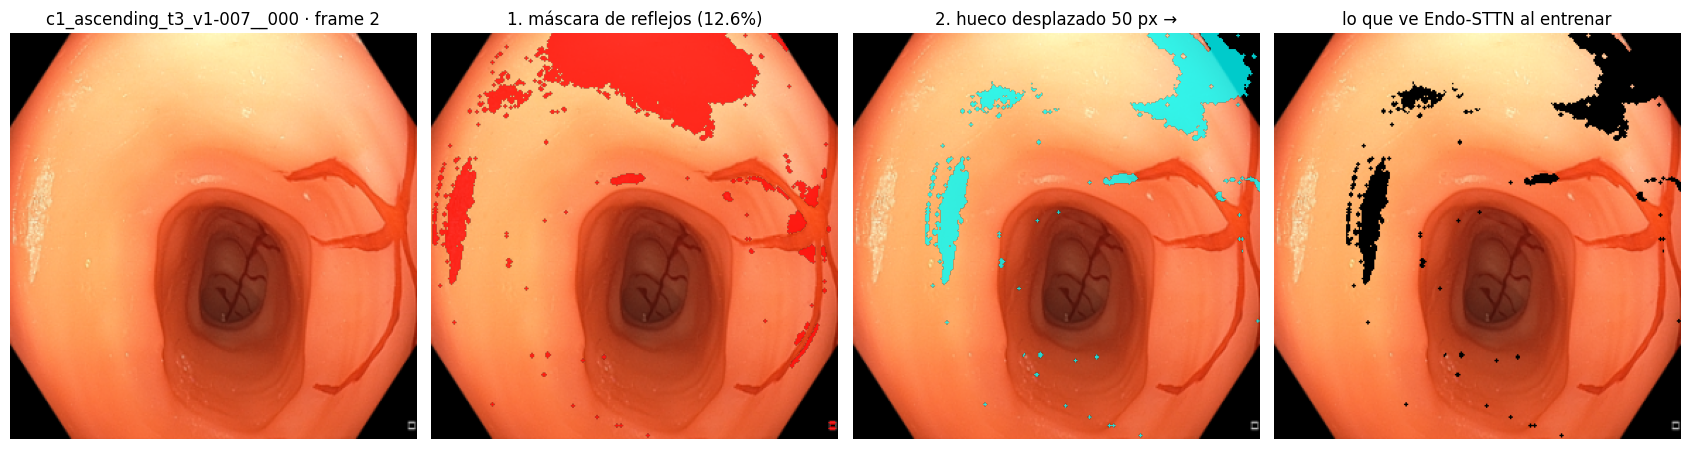

Endo-STTN debe reconstruir el hueco (azul); su color real se conoce, así que se puede medir el error.


In [4]:
# Las dos máscaras en un frame de entrenamiento
trozo = sorted((ec.DIR_DATASET / "JPEGImages").glob("*.zip"))[0].stem
leer = lambda carpeta, i: np.array(Image.open(zipfile.ZipFile(ec.DIR_DATASET / carpeta / f"{trozo}.zip").open(f"{i:05d}.png")))
n = json.load(open(ec.DIR_DATASET / "train.json"))[trozo]
masks = [leer("Annotations", i) > 127 for i in range(n)]
i = int(np.argmax([m.sum() for m in masks]))
frame, mask = leer("JPEGImages", i), masks[i]
hueco = ec.hueco_pseudo(mask)
entrada = frame.copy(); entrada[hueco] = 0

fig, ax = plt.subplots(1, 4, figsize=(17, 4.6))
ax[0].imshow(frame); ax[0].set_title(f"{trozo} · frame {i}")
ax[1].imshow(frame); ax[1].imshow(np.ma.masked_where(~mask, mask), cmap="autumn", alpha=0.8)
ax[1].set_title(f"1. máscara de reflejos ({100 * mask.mean():.1f}%)")
ax[2].imshow(frame); ax[2].imshow(np.ma.masked_where(~hueco, hueco), cmap="cool", alpha=0.8)
ax[2].set_title(f"2. hueco desplazado {ec.DESPLAZAMIENTO} px →")
ax[3].imshow(entrada); ax[3].set_title("lo que ve Endo-STTN al entrenar")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("Endo-STTN debe reconstruir el hueco (azul); su color real se conoce, así que se puede medir el error.")

### Revisión de las máscaras (paso 2 del checklist)

Primero, la máscara elegida (`MASCARA`) junto a El Meslouhi (2011), el método de los autores, sobre los mismos frames. Después,
**50 frames de entrenamiento al azar** con la máscara usada, para revisar a ojo que marquen reflejos y no residuos,
tejido claro u otra cosa. La figura se guarda en `resultados/revision_mascaras.png`.

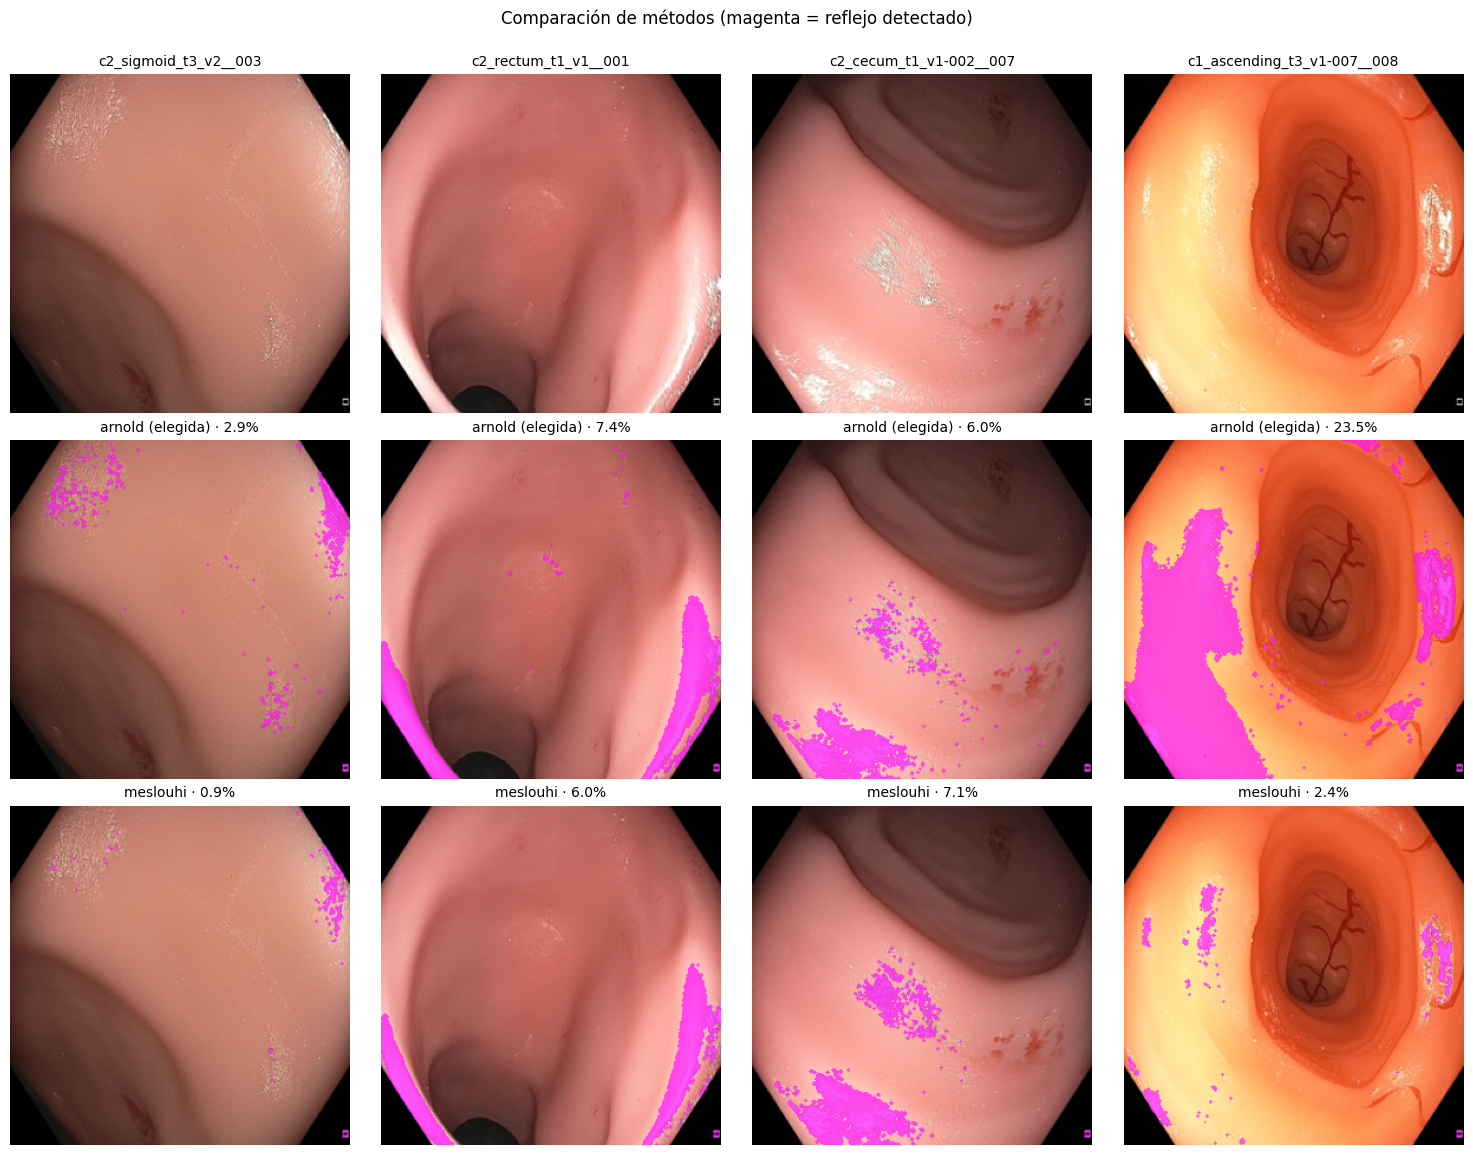

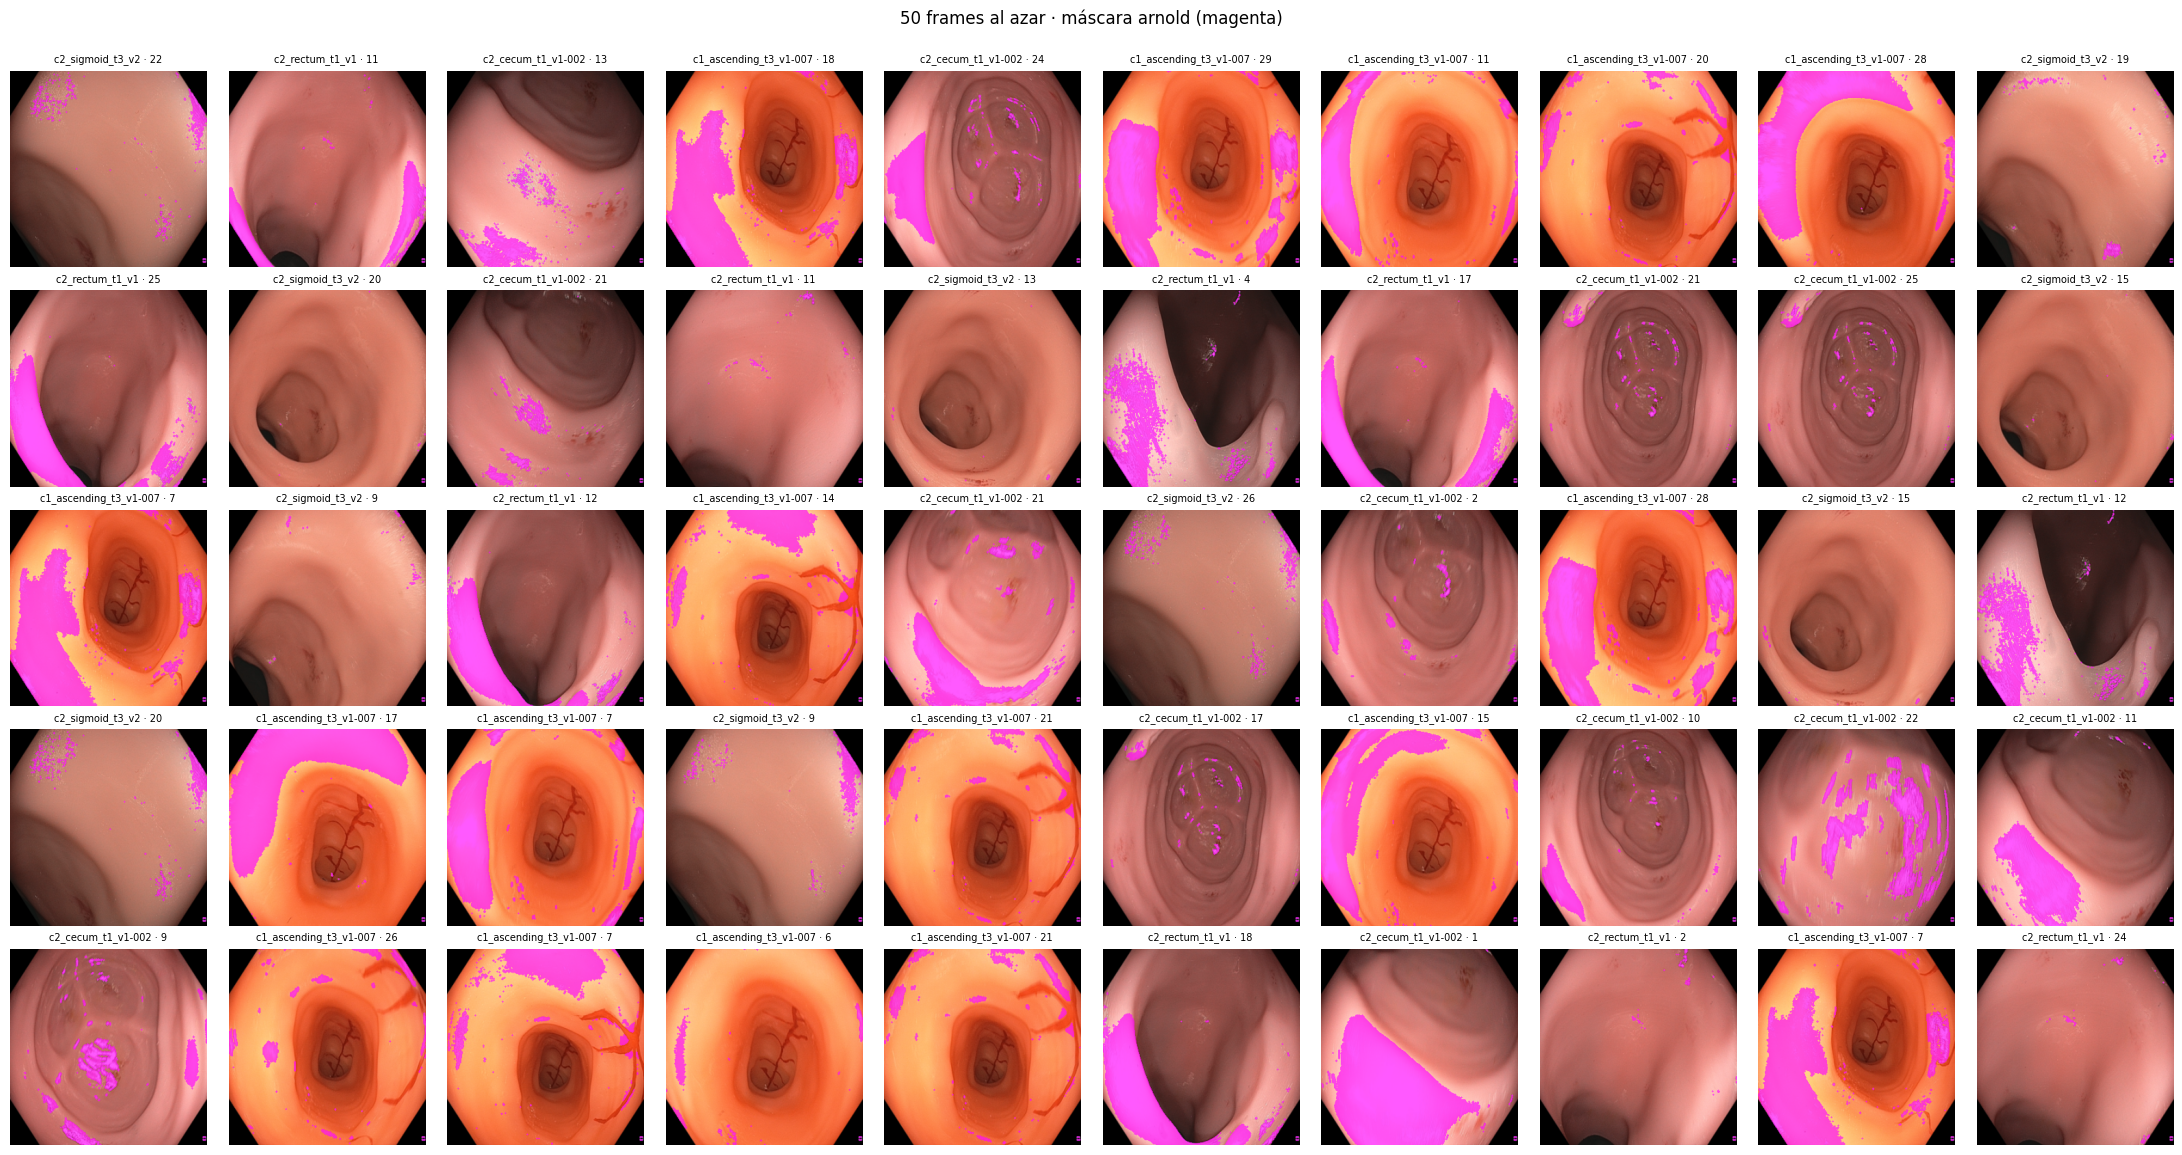

In [5]:
trozos = json.load(open(ec.DIR_DATASET / "train.json"))
rng = np.random.default_rng(0)
muestra = [(t, int(rng.integers(n))) for t, n in (list(trozos.items())[k] for k in rng.integers(len(trozos), size=50))]
color = np.array([255, 0, 255], np.uint8)   # magenta: se distingue de los reflejos blancos y del tejido

def con_mascara(img, m):
    out = img.copy(); out[m] = (0.35 * out[m] + 0.65 * color).astype(np.uint8); return out

# 1. Los dos métodos sobre 4 frames (se recalculan desde el frame de 288x288)
fig, ax = plt.subplots(3, 4, figsize=(15, 11.5))
for j, (t, i) in enumerate(muestra[:4]):
    f = np.array(Image.open(zipfile.ZipFile(ec.DIR_DATASET / "JPEGImages" / f"{t}.zip").open(f"{i:05d}.png")))
    otro = "meslouhi" if MASCARA != "meslouhi" else "hsv"
    m_sel = getattr(ec, f"mascara_{MASCARA}")(f) if MASCARA != "umbral" else ec.frame_y_mascara(f, "umbral")[1]
    m_otro = getattr(ec, f"mascara_{otro}")(f)
    for r, (img, tit) in enumerate([(f, t), (con_mascara(f, m_sel), f"{MASCARA} (elegida) · {100 * m_sel.mean():.1f}%"),
                                    (con_mascara(f, m_otro), f"{otro} · {100 * m_otro.mean():.1f}%")]):
        ax[r, j].imshow(img); ax[r, j].set_title(tit, fontsize=10); ax[r, j].axis("off")
plt.suptitle("Comparación de métodos (magenta = reflejo detectado)", y=1.0); plt.tight_layout(); plt.show()

# 2. 50 máscaras al azar con el método elegido
fig, ax = plt.subplots(5, 10, figsize=(22, 11.5))
for a, (t, i) in zip(ax.ravel(), muestra):
    z = lambda c: zipfile.ZipFile(ec.DIR_DATASET / c / f"{t}.zip").open(f"{i:05d}.png")
    f, m = np.array(Image.open(z("JPEGImages"))), np.array(Image.open(z("Annotations"))) > 127
    a.imshow(con_mascara(f, m)); a.set_title(f"{t.split('__')[0]} · {i}", fontsize=7); a.axis("off")
plt.suptitle(f"50 frames al azar · máscara {prep['mascara']} (magenta)", y=1.0); plt.tight_layout()
ec.DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
plt.savefig(ec.DIR_RESULTADOS / "revision_mascaras.png", dpi=80, bbox_inches="tight"); plt.show()

> **Interpretación · máscaras.** Arnold marca mucha más área que El Meslouhi en algunos videos: en `c1_ascending`
> llega a **23.5 % del frame contra 2.4 %**. En la cuadrícula de 50 frames se ve que en ese video pinta de magenta
> zonas grandes de **pared amarilla clara que no son reflejos** (tejido bien iluminado, brillo difuso); pasa lo mismo,
> en menor medida, en los bordes de `rectum` y `cecum`. Consecuencias:
> 1. **Entrenamiento:** huecos enormes y poco realistas, y se le pide al modelo "borrar" tejido normal.
>    `c1_ascending` es el video que más pesa (15.5 % de área marcada).
> 2. **Evaluación:** la máscara también define el hueco desplazado (`hueco_pseudo` la mueve 50 px y le quita los
>    reflejos *detectados*). Con otra máscara los huecos son otros, así que **las cifras de este notebook no se
>    comparan directamente con las del notebook de El Meslouhi**, aunque usen los mismos videos.

## 2. Entrenamiento

Se usa el entrenamiento original de Endo-STTN (`Endo-STTN/core/trainer.py`) sin modificarlo:
- **Pérdidas:** L1 dentro del hueco, L1 en el resto de la imagen y pérdida adversarial (hinge, peso 0.01).
- **Optimizador:** Adam con lr 1e-4 y betas (0, 0.99).
- **Clips:** de 5 frames, a veces consecutivos y a veces al azar dentro del mismo video.

El generador arranca con `gen_00009.pth`. El discriminador arranca desde cero, porque el modelo publicado no lo trae.
Cada `GUARDAR_CADA` iteraciones se guarda `gen_XXXXX.pth`. Si el entrenamiento se interrumpe, al volver a correr esta
celda continúa desde el último checkpoint.

In [6]:
if CORRER_ENTRENAR:
    correr(A31 / "entrenar_endosttn.py", "--pesos", PESOS_ORIGINALES, "--iteraciones", ITERACIONES,
           "--guardar-cada", GUARDAR_CADA, "--lote", LOTE)
print(sorted(p.name for p in ec.DIR_ENTRENAMIENTO.glob("gen_[0-9]*.pth")))

Bitácora: {'fecha': '2026-10-22T00:17', 'gpu_nombre': 'NVIDIA A100-SXM4-80GB', 'mascara': 'arnold'}
Endo-STTN: 32 trozos (942 frames) | lote 4 | 2000 iteraciones | cuda:0
Loading model from /content/repo/modelos/endosttn_c3vd/inicio/sttn.pth...
Warnning: There is no trained model found. An initialized model will be used.

d: 0.993; g: -0.003;hole: 0.039; valid: 0.022:  24%|██▍       | 478/2000 [04:20<13:47,  1.84it/s]
saving model to /content/repo/modelos/endosttn_c3vd/gen_00001.pth ...

d: 1.012; g: -0.004;hole: 0.024; valid: 0.016:  46%|████▌     | 921/2000 [08:20<09:45,  1.84it/s]
saving model to /content/repo/modelos/endosttn_c3vd/gen_00002.pth ...

d: 1.008; g: 0.000;hole: 0.019; valid: 0.015:  74%|███████▍  | 1476/2000 [13:20<04:43,  1.85it/s]
saving model to /content/repo/modelos/endosttn_c3vd/gen_00003.pth ...

d: 0.994; g: 0.002;hole: 0.096; valid: 0.022:  96%|█████████▌| 1919/2000 [17:20<00:43,  1.85it/s] 
saving model to /content/repo/modelos/endosttn_c3vd/gen_00004.pth ...


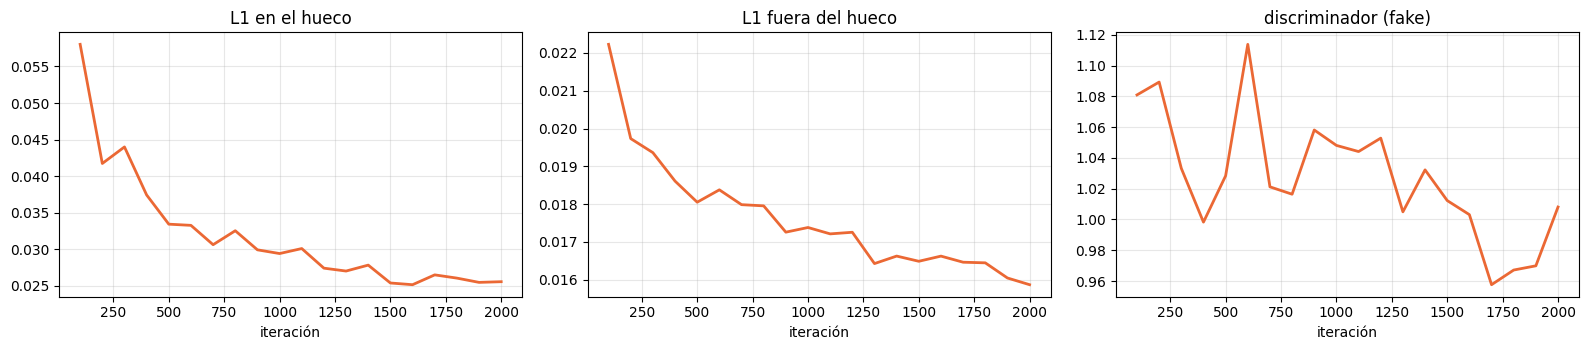

In [7]:
# Curvas de pérdida (TensorBoard de Endo-STTN; se promedian cada 100 iteraciones)
try:
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    for a, (sub, tag, titulo) in zip(ax, [("gen", "loss/hole_loss", "L1 en el hueco"),
                                          ("gen", "loss/valid_loss", "L1 fuera del hueco"),
                                          ("dis", "loss/dis_vid_fake", "discriminador (fake)")]):
        ea = EventAccumulator(str(ec.DIR_ENTRENAMIENTO / sub)); ea.Reload()
        ev = ea.Scalars(tag) if tag in ea.Tags()["scalars"] else []
        a.plot([e.step for e in ev], [e.value for e in ev], color=COLOR["reentrenado"], lw=2)
        a.set_title(titulo); a.set_xlabel("iteración"); a.grid(alpha=0.3)
    if ev: plt.tight_layout(); plt.show()
    else: plt.close(fig); print("Aún no hay puntos: Endo-STTN registra las pérdidas cada 100 iteraciones.")
except Exception as e:
    print("No se pudieron leer las curvas de TensorBoard:", e)

> **Interpretación · curvas de pérdida.**
> - **L1 en el hueco** baja de 0.058 a ≈0.025 y se aplana desde ≈1500 iteraciones; **L1 fuera del hueco** baja de
>   0.022 a 0.016. El generador sí se adapta al dominio de C3VDv2 (textura, color y reflejos de la silicona).
> - **Discriminador:** `d ≈ 1.0` y `g ≈ 0` durante todo el entrenamiento. Con pérdida hinge, d ≈ 1 significa que el
>   discriminador apenas distingue lo real de lo falso; además la pérdida adversarial pesa solo 0.01. En la práctica
>   esto fue un **ajuste fino por L1**: mejora la reconstrucción del color, no el "realismo" adversarial. Es lo
>   esperable con pocas iteraciones y un discriminador que parte desde cero.
> - El aviso `Warnning: There is no trained model found` no es un problema: lo imprime la función que busca
>   checkpoints para *reanudar* (`Endo-STTN/core/trainer.py`) y no había ninguno. El generador sí se cargó desde
>   `inicio/sttn.pth` (= `gen_00009.pth`); lo confirma que a las 500 iteraciones ya supera al original en validación,
>   algo imposible partiendo de pesos aleatorios.

## 3. Evaluación: original vs reentrenado

Se mide en el hueco desplazado de videos que Endo-STTN no vio al entrenar, como en `quantifyResults.ipynb` de
Endo-STTN: **PSNR** (dB) y **SSIM** (0–1), mayor es mejor; además **MAE** (0–255), menor es mejor. Con la validación se elige el mejor checkpoint (`gen_mejor.pth`). Con la prueba se
compara contra el original, frame por frame.

In [8]:
if CORRER_EVALUAR:
    correr(A31 / "evaluar_endosttn.py", "--pesos-originales", PESOS_ORIGINALES)
display(Markdown(open(ec.DIR_RESULTADOS / "resumen.md").read()))

validación original   (iteración      0): MAE 5.10 | PSNR 30.37 dB | SSIM 0.8724
validación gen_00001  (iteración    500): MAE 4.54 | PSNR 32.34 dB | SSIM 0.9146
validación gen_00002  (iteración   1000): MAE 4.18 | PSNR 33.21 dB | SSIM 0.9182
validación gen_00003  (iteración   1500): MAE 4.41 | PSNR 32.60 dB | SSIM 0.9105
validación gen_00004  (iteración   2000): MAE 4.50 | PSNR 32.88 dB | SSIM 0.9087
Reentrenado = gen_00002 (iteración 1000) -> /content/repo/modelos/endosttn_c3vd/gen_mejor.pth

                psnr    ssim     mae
modelo                              
original     29.0941  0.8409  6.8848
reentrenado  30.3332  0.8901  5.7386
Wilcoxon psnr: p = 3.846e-14 (256 frames)
Wilcoxon ssim: p = 4.82e-44 (256 frames)
Wilcoxon mae: p = 1.319e-18 (256 frames)
Resultados -> /content/drive/MyDrive/Equipo19/re_entrenar_endo/mascara_arnold/resultados


# Avance 3 · Endo-STTN original vs reentrenado con C3VDv2

Videos de validación: c2_transverse1_t1_v1-003  
Videos de prueba: c2_descending_t4_v2, c2_descending_t4_v3  
Reentrenado: `gen_00002.pth` (iteración 1000)  
Máscaras: arnold · frames: 1 de cada 1 · lote 4 · lr 0.0001 · GPU: NVIDIA A100-SXM4-80GB · entrenamiento iniciado: 2026-10-22T00:17

## Prueba: error del relleno en el hueco desplazado (pseudo ground truth)

PSNR en dB y SSIM (0-1): mayor es mejor. MAE en valores de color 0-255: menor es mejor.

| modelo      |    psnr |   ssim |    mae |
|:------------|--------:|-------:|-------:|
| original    | 29.0941 | 0.8409 | 6.8848 |
| reentrenado | 30.3332 | 0.8901 | 5.7386 |

Wilcoxon pareado por frame (H1: el reentrenado es mejor):

| metrica   |   frames |   mediana_dif (reentrenado - original) |   p_valor |
|:----------|---------:|---------------------------------------:|----------:|
| psnr      |      256 |                                1.335   | 3.846e-14 |
| ssim      |      256 |                                0.04651 | 4.82e-44  |
| mae       |      256 |                               -1.126   | 1.319e-18 |

## Validación por checkpoint

| modelo    |   iteracion |    mae |    psnr |   ssim |   frames |
|:----------|------------:|-------:|--------:|-------:|---------:|
| original  |           0 | 5.1034 | 30.3725 | 0.8724 |      398 |
| gen_00001 |         500 | 4.5382 | 32.3436 | 0.9146 |      398 |
| gen_00002 |        1000 | 4.1768 | 33.215  | 0.9182 |      398 |
| gen_00003 |        1500 | 4.4115 | 32.5999 | 0.9105 |      398 |
| gen_00004 |        2000 | 4.5038 | 32.8795 | 0.9087 |      398 |


> **Interpretación · prueba (`c2_descending_t4` v2 y v3, no vistos al entrenar).**
>
> | | PSNR ↑ | SSIM ↑ | MAE ↓ |
> |---|---|---|---|
> | original (`gen_00009`) | 29.09 dB | 0.841 | 6.88 |
> | reentrenado (`gen_00002`, iter 1000) | **30.33 dB** | **0.890** | **5.74** |
> | diferencia | +1.24 dB | +0.049 | −1.15 (≈17 % menos error) |
>
> - **Las tres métricas mejoran a la vez.** +1.2 dB de PSNR es una mejora real pero moderada; la de SSIM es la más
>   clara: el relleno conserva mejor la estructura (gradientes de color y bordes de los pliegues).
> - **Valores p de Wilcoxon (10⁻¹⁴ a 10⁻⁴⁴).** Indican que la mejora es consistente frame por frame, pero los 256
>   frames **no son independientes**: vienen de 2 videos del mismo segmento y los frames consecutivos son casi
>   iguales. Los p exageran la certeza; conviene decir "mejora consistente en todos los frames de prueba", no
>   "evidencia contundente". En el fondo la prueba es **un solo segmento**.

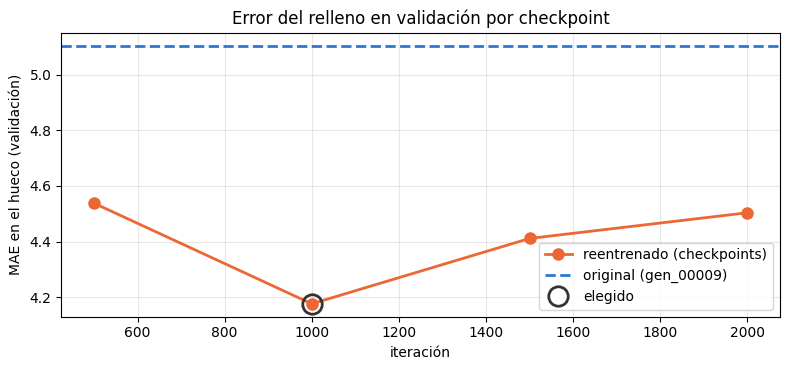

In [9]:
ruta_val = ec.DIR_RESULTADOS / "validacion_por_checkpoint.csv"
if ruta_val.exists():
    val = pd.read_csv(ruta_val)
    orig, ck = val[val.modelo == "original"].iloc[0], val[val.modelo != "original"]
    mejor = json.load(open(ec.DIR_ENTRENAMIENTO / "mejor.json"))
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(ck.iteracion, ck.mae, "-o", color=COLOR["reentrenado"], lw=2, ms=8, label="reentrenado (checkpoints)")
    ax.axhline(orig.mae, color=COLOR["original"], lw=2, ls="--", label="original (gen_00009)")
    ax.plot([mejor["iteracion"]], [ck[ck.modelo == mejor["checkpoint"]].mae.iloc[0]], "o", ms=14,
            mfc="none", mec="#333333", mew=2, label="elegido")
    ax.set_xlabel("iteración"); ax.set_ylabel("MAE en el hueco (validación)"); ax.grid(alpha=0.3); ax.legend()
    ax.set_title("Error del relleno en validación por checkpoint")
    plt.tight_layout(); plt.show()

> **Interpretación · validación por checkpoint.**
>
> | iteración | MAE | PSNR |
> |---|---|---|
> | 0 (original) | 5.10 | 30.37 dB |
> | 500 | 4.54 | 32.34 dB |
> | **1000 (elegido)** | **4.18** | **33.21 dB** |
> | 1500 | 4.41 | 32.60 dB |
> | 2000 | 4.50 | 32.88 dB |
>
> Casi toda la ganancia llega en las primeras 500–1000 iteraciones. Después la validación empeora un poco aunque la
> pérdida de entrenamiento sigue bajando: es un **inicio de sobreajuste** a un conjunto de entrenamiento pequeño
> (4 videos, 942 frames). Quedarse con la iteración 1000 es correcto; entrenar más no ayudaría. Como la validación es
> un solo video (`transverse1`), la diferencia entre 1000 y 2000 (MAE 4.18 vs 4.50) puede ser en parte ruido.

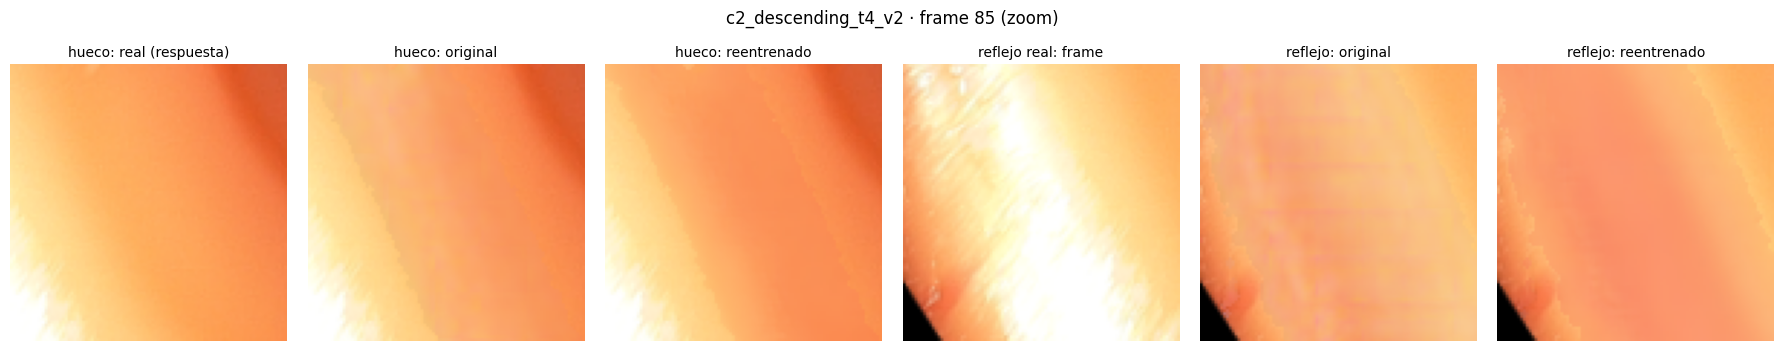

original     en el hueco de este frame: PSNR 29.32 dB | SSIM 0.908 | MAE 6.6
reentrenado  en el hueco de este frame: PSNR 30.19 dB | SSIM 0.951 | MAE 5.7


In [10]:
# Ejemplo visual en un video de prueba: hueco desplazado (se conoce la respuesta) y reflejos reales
div = json.load(open(ec.DIR_DATASET / "division.json"))
video = div["prueba"][0]
rgb, mask = np.load(ec.DIR_EVAL / video / "rgb.npy"), np.load(ec.DIR_EVAL / video / "mask.npy")
hueco = ec.hueco_pseudo(mask)
i = int(np.argmax(hueco.reshape(len(hueco), -1).sum(1)))
modelos = {"original": le.cargar(PESOS_ORIGINALES, DEVICE),
           "reentrenado": le.cargar(ec.DIR_ENTRENAMIENTO / "gen_mejor.pth", DEVICE)}
ini = max(0, i - 10)
seg = slice(ini, min(len(rgb), i + 11))
rell = {k: le.limpiar_video(m, rgb[seg], hueco[seg], DEVICE)[i - ini] for k, m in modelos.items()}
limp = {k: le.limpiar_video(m, rgb[seg], mask[seg], DEVICE)[i - ini] for k, m in modelos.items()}

def zoom(m, lado=96):
    ys, xs = np.nonzero(m[i]) if m[i].any() else (np.array([144]), np.array([144]))
    cy, cx = int(np.median(ys)), int(np.median(xs))
    y0, x0 = np.clip(cy - lado // 2, 0, 288 - lado), np.clip(cx - lado // 2, 0, 288 - lado)
    return lambda a: a[y0:y0 + lado, x0:x0 + lado]

zh, zm = zoom(hueco), zoom(mask)
paneles = [("hueco: real (respuesta)", zh(rgb[i])), ("hueco: original", zh(rell["original"])),
           ("hueco: reentrenado", zh(rell["reentrenado"])),
           ("reflejo real: frame", zm(rgb[i])), ("reflejo: original", zm(limp["original"])),
           ("reflejo: reentrenado", zm(limp["reentrenado"]))]
fig, ax = plt.subplots(1, 6, figsize=(18, 3.4))
for a, (t, img) in zip(ax, paneles):
    a.imshow(img); a.set_title(t, fontsize=10); a.axis("off")
plt.suptitle(f"{video} · frame {i} (zoom)", y=1.02); plt.tight_layout(); plt.show()
for k in modelos:
    m = ec.metricas_hueco(rell[k], rgb[i], hueco[i])
    print(f"{k:12s} en el hueco de este frame: PSNR {m['psnr']:.2f} dB | SSIM {m['ssim']:.3f} | MAE {m['mae']:.1f}")

> **Interpretación · ejemplo visual.**
> - **Hueco desplazado:** el original deja manchas rosadas y una textura que no corresponde; el reentrenado reproduce
>   mejor el degradado naranja y el borde oscuro.
> - **Reflejo real:** el original rellena con una textura rosa pálida con artefactos y franjas; el reentrenado da un
>   color más uniforme y coherente con el tejido de alrededor, aunque algo más **liso y rojizo**. Aquí no hay
>   respuesta correcta, así que este panel solo se juzga a ojo.
> - En "hueco: real (respuesta)" hay una esquina blanca: un reflejo que la máscara no detectó y que quedó como
>   respuesta "correcta". El reentrenado la copia, es decir, aprende a reproducir reflejos y la métrica lo premia.

## 4. Resultados y siguiente paso

Los resultados quedan en `MyDrive/Equipo19/re_entrenar_endo/resultados/` y el modelo elegido en
`MyDrive/Equipo19/re_entrenar_endo/modelos/gen_mejor.pth` (mismo formato que `gen_00009.pth`).

Para el reporte, sube a GitHub `resumen.md`, `validacion_por_checkpoint.csv`, `prueba_por_frame.csv`,
`revision_mascaras.png` y este notebook ejecutado, a `Avance3_ReEntrenar_Endo/resultados/`. La configuración usada
(GPU, fecha, máscara, iteraciones) queda en `modelos/config.json` y al inicio de `resumen.md`, para la bitácora.



In [11]:
mejor = json.load(open(ec.DIR_ENTRENAMIENTO / "mejor.json"))
print("Modelo elegido:", mejor, "->", ec.DIR_ENTRENAMIENTO / "gen_mejor.pth")
cfg = json.load(open(ec.DIR_ENTRENAMIENTO / "config.json"))
print("Bitácora      :", {k: cfg.get(k) for k in ["fecha", "gpu_nombre", "mascara", "paso"]},
      "| iteraciones", cfg["trainer"]["iterations"], "| lote", cfg["trainer"]["batch_size"])
print("Resultados    :", sorted(p.name for p in ec.DIR_RESULTADOS.iterdir()), "en", ec.DIR_RESULTADOS)

Modelo elegido: {'checkpoint': 'gen_00002', 'iteracion': 1000} -> /content/repo/modelos/endosttn_c3vd/gen_mejor.pth
Bitácora      : {'fecha': '2026-10-22T00:17', 'gpu_nombre': 'NVIDIA A100-SXM4-80GB', 'mascara': 'arnold', 'paso': 1} | iteraciones 2000 | lote 4
Resultados    : ['prueba_por_frame.csv', 'resumen.md', 'revision_mascaras.png', 'validacion_por_checkpoint.csv'] en /content/drive/MyDrive/Equipo19/re_entrenar_endo/mascara_arnold/resultados


**Siguiente paso (paso 6 del checklist):** limpiar los frames del Avance 2 con `gen_mejor.pth`
(`python codigo/limpiar_endosttn.py --pesos .../gen_mejor.pth`) y ajustar el estimador de profundidad con ellos, para
ver si el mejor relleno también mejora la profundidad respecto al modelo D.

## 5. Interpretación de los resultados

**Conclusión:** el reentrenamiento funcionó. Reentrenar Endo-STTN 1000 iteraciones con frames de C3VDv2 y la máscara
de Arnold mejora el relleno en videos no vistos (**PSNR +1.2 dB, SSIM +0.05, MAE −17 %**), con mejora consistente
frame por frame. La mejora viene sobre todo de adaptar el color y la textura al dominio (pérdida L1); el componente
adversarial casi no participó. Entrenar más allá de 1000 iteraciones empieza a sobreajustar.

**Limitaciones:**
- La prueba es un solo segmento (`c2_descending_t4`, 2 videos) y la validación un solo video; los valores p de
  Wilcoxon exageran la certeza porque los frames están correlacionados.
- La máscara de Arnold marca como reflejo tejido claro en algunos videos (sobre todo `c1_ascending`), lo que agranda
  los huecos de entrenamiento.
- El hueco de evaluación depende de la máscara, así que esta corrida **no se compara directamente** con la de
  El Meslouhi. Para decidir qué máscara entrena mejor hay que evaluar los dos modelos con el **mismo** hueco
  (por ejemplo, el de El Meslouhi en ambos).